# Классификация обращений клиентов RUDATA. Подход 2: локальная языковая модель и гибрид

НАЗВАНИЕ ПРОЕКТА: Интеллектуальная классификация и анализ клиентских обращений (задача 2.2.3)

В первом ноутбуке (`classify_classic.ipynb`) обращения классифицирует градиентный бустинг на TF-IDF.
Он хорошо определяет интерфейс и продукт, но плохо — тематику: в validation и test тематики
сформулированы другими словами, чем в train, а модель на словах переносит на новые формулировки
только то, что видела.

В этом ноутбуке:
- **подход 2** — локальная языковая модель (LLM) `qwen3:8b`, запущенная через Ollama на этом же компьютере.
  Модель не обучаем на разметке, а объясняем ей задачу словами: даём определения классов из справочника
  и несколько примеров. Тексты обращений не покидают компьютер;
- **подход 3** — гибрид: каждое поле определяет тот подход, который лучше справляется с ним на validation;
- **сравнение трёх подходов** на test по качеству, скорости и ресурсам.

## Как работает подход с LLM

Объект и целевые переменные те же: одно обращение, три поля — `interface`, `product`, `topic`.

1. **Промпт.** Модель получает инструкцию: определения всех классов из `dictionary.csv`
   (описание и правило разметки), ключевые правила из описания набора данных и 13 примеров
   из train — по одному на каждую тематику.
2. **Ответ строго из справочника.** Вместе с запросом передаётся JSON-схема ответа: в каждом поле —
   только допустимые коды. Для продукта список дополнительно ограничен доступами логина:
   подключённые продукты, `NO_PRODUCT` и `UNKNOWN` (последний — только при 2+ подключённых продуктах,
   как в разметке). Выдумать класс или выбрать неподключённый продукт модель не может.
3. **Уверенность.** Модель пишет ответ по кусочкам (токенам) и для каждого кусочка знает вероятность.
   Ollama возвращает эти вероятности вместе с ответом (параметр `logprobs`). Уверенность в поле —
   вероятность того, что модель написала именно этот код: например, AVAILABILITY 0,92 значит, что
   на остальные тематики модель оставила 0,08. Это аналог `predict_proba` у бустинга, хватает одного запроса.

   Сначала пробовали другой способ — спрашивать модель 3 раза со случайностью и считать долю совпавших
   ответов. Он не сработал: в 827 из 830 обращений validation все 3 ответа совпали, уверенность почти
   всегда была 1,0 и не отделяла ошибки, а время выросло втрое.
4. **Гибрид.** Каждое поле берётся у подхода, лучшего для него на validation. Уверенность для интерфейса
   и продукта — **согласие LLM и бустинга**: если два независимых подхода дали один ответ, он почти всегда
   верен, если разные — поле уходит на ручную проверку. Для тематики согласие не помогает: бустинг
   в ней сам часто ошибается, и несогласие не означает ошибку LLM. Поэтому уверенность в тематике —
   вероятность из LLM. Насколько согласие отделяет ошибки, показано ниже на validation.
5. **Ручная проверка — по тем же правилам, что в первом подходе:** `UNKNOWN` в каком-либо поле,
   уверенность ниже порога поля или противоречие полей; для продукта — правило заказчика
   «нет уверенности → `UNKNOWN`». Пороги подбираются на validation.

Как и в первом подходе: настройки выбираем по validation, test — только для финальной оценки.

## Загрузка необходимых библиотек

In [1]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import os  # пути к файлам
import json  # схема ответа, ответы модели
import time  # замер скорости
import re  # поиск значения поля в тексте ответа модели

# LLM
import requests  # запросы к Ollama — локальному серверу языковой модели

# Метрики
from sklearn.metrics import accuracy_score, f1_score  # accuracy и macro-F1
from sklearn.metrics import classification_report  # отчёт по классам

pd.set_option('display.max_colwidth', 200)  # показываем тексты обращений целиком

Константы

In [2]:
rand_state = 42  # фиксируем random_state и seed модели

FIELDS = ['interface', 'product', 'topic']  # три поля, которые классифицируем
SPECIFIC_PRODUCTS = ['RD_RISK', 'RD_SOLVENCY', 'RDFOR', 'RD_SCORE', 'RD_AFFILIATE', 'SPPI_TEST']  # шесть продуктов

OLLAMA_URL = 'http://localhost:11434'  # адрес Ollama на этом компьютере
MODEL = 'qwen3:8b'  # языковая модель
NUM_CTX = 8192  # сколько токенов модель видит за один запрос (промпт + обращение + ответ)

TARGET_AUTO_ACCURACY = 0.95  # какую точность поля хотим среди принятых автоматически
THRESHOLD_GRID = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]  # какие пороги уверенности перебираем
AGREEMENT_FIELDS = ['interface', 'product']  # в гибриде уверенность в этих полях — согласие LLM и бустинга

os.makedirs('results', exist_ok=True)

## Загрузка данных

Справочник доступов `models/access.json` и прогнозы бустинга `results/classic_predictions_*.csv`
создаёт первый ноутбук, поэтому он запускается раньше этого

In [3]:
appeals = pd.read_csv('data/raw/appeals.csv', encoding='utf-8-sig', parse_dates=['created_at'])
dictionary = pd.read_csv('data/raw/dictionary.csv', encoding='utf-8-sig')

with open('models/access.json', encoding='utf-8') as f:
    access = json.load(f)

# доступы берём из справочника по логину — так же, как будет делать сервис
appeals['available_products'] = appeals['client_id'].map(access)

train = appeals[appeals['split'] == 'train']
valid = appeals[appeals['split'] == 'validation']
test = appeals[appeals['split'] == 'test']

classes = {field: dictionary.loc[dictionary['field'] == field, 'code'].tolist() for field in FIELDS}

display(f'train {len(train)}, validation {len(valid)}, test {len(test)}, логинов в справочнике {len(access)}')

'train 3030, validation 830, test 905, логинов в справочнике 240'

## Подключение к Ollama

Ollama работает на компьютере как маленький сервер: ему отправляют запрос по адресу `localhost:11434`
и получают ответ модели. Проверим, что сервер запущен и модель скачана

In [4]:
models_in_ollama = [model['name'] for model in requests.get(f'{OLLAMA_URL}/api/tags', timeout=10).json()['models']]
display(f'Модели в Ollama: {models_in_ollama}')
display(f'{MODEL} установлена: {MODEL in models_in_ollama}')

"Модели в Ollama: ['qwen3:8b']"

'qwen3:8b установлена: True'

## Промпт

Промпт состоит из двух частей:
- **системная инструкция** — одинакова для всех обращений: задача, определения классов, правила, примеры.
  Ollama запоминает её обработку между запросами, поэтому длинная инструкция почти не замедляет работу;
- **сообщение с обращением** — подключённые продукты логина и текст обращения.

Определения классов берём из справочника: код, название, описание и правило разметки

In [5]:
def describe_field(field):
    rows = dictionary[dictionary['field'] == field]
    lines = []
    for row in rows.itertuples():
        # фраза повторяется у каждой тематики и не помогает различать классы
        rule = row.annotation_rule.replace(' Тематика — учебный классификатор, не официальный тип заявки RUDATA.', '')
        lines.append(f'- {row.code} ({row.name}): {row.description} Правило: {rule}')
    return '\n'.join(lines)


print(describe_field('interface'))

- API (API RUDATA): Удалённые HTTP/REST-запросы, JSON, токен, Swagger. Правило: HTTP API; не COM/VBA в Excel. В данной учебной онтологии продукт NO_PRODUCT.
- WEB (WEB RUDATA): Сайт, браузерный поиск и портфель. Правило: Проблема на сайте; выгрузка из сайта в Excel остаётся WEB.
- EXCEL_ADDIN (Надстройка Excel Add-In): Установка, активация, функции, COM API, соединение надстройки. Правило: Общий уровень надстройки, не содержимое готового расчётного шаблона.
- EXCEL_TEMPLATE (Шаблон Excel Add-In): Готовая книга/шаблон расчёта или получения данных. Правило: Работа конкретного шаблона; не отдельная HTTP-ручка.
- EFIR (Терминал ЭФИР): Установленное терминальное приложение. Правило: Не любая надстройка с названием ЭФИР, а самостоятельный терминал.
- NONE (Не относится к интерфейсу): Организационный, договорной либо чисто методологический вопрос без привязки к среде. Правило: Среда не нужна для смысла запроса, например условия лицензии. Не синоним UNKNOWN.
- UNKNOWN (Интерфейс не определён):

Примеры для промпта — по одному обращению из train на каждую тематику. В примере показываем
подключённые продукты и правильный ответ в том же формате, в каком ждём ответ от модели

In [6]:
def format_products(available):
    return ', '.join(available) if available else 'нет подключённых продуктов'


def user_message(text, available):
    return f'Подключённые продукты клиента: {format_products(available)}\nОбращение: {text}'


examples = train.groupby('topic').sample(1, random_state=rand_state)

examples_text = '\n\n'.join(
    user_message(row['text'], row['available_products']) + '\nОтвет: '
    + json.dumps({field: row[field] for field in FIELDS}, ensure_ascii=False)
    for _, row in examples.iterrows())

examples[['text'] + FIELDS]

,text,interface,product,topic
447,"Коллеги, добрый день.\n\nРечь о терминале ЭФИР, не об Excel. Настольный терминал не принимает мой логин и пароль. Нужна проверка доступа к приложению.\n\nПока не передаю конфиденциальные сведения;...",EFIR,NO_PRODUCT,AUTH_ACCESS
673,Добрый день!\n\nПроблема на уровне Add-In для Excel. Надстройка не открывает каталог готовых книг: вместо списка ошибка. Проблема на общем уровне Add-In.\n\nХотим разобраться до следующей регулярн...,EXCEL_ADDIN,NO_PRODUCT,AVAILABILITY
1966,"Коллеги, добрый день.\nAPI RUDATA, наш программный клиент. При переносе ответа API в нашу базу портятся русские названия. Исходный JSON читается; вопрос к настройке кодировок.\nБуду благодарен за ...",API,NO_PRODUCT,CONFIG_INTEGRATION
806,По подписке РДФОР просим согласовать продление и перечень передаваемых документов.,NONE,RDFOR,CONTRACT
1914,"Использую готовую книгу сервиса в Excel. В РД Скор расходятся два результата LGD для одного контрагента и срока. Просим проверить конкретный расчёт, а не объяснить значение термина. Просим подсказ...",EXCEL_TEMPLATE,RD_SCORE,DATA_DISCREPANCY
664,"Коллеги, добрый день.\n\nС сервисом «RD Solvency» проблем нет. Работаю в расчётной книге, загруженной из надстройки Excel. РД Скор: по нескольким компаниям нет оценки PD, хотя строки контрагентов ...",EXCEL_TEMPLATE,RD_SCORE,DATA_MISSING
1471,"Здравствуйте.\n\nРаботаю в расчётной книге, загруженной из надстройки Excel. Для РД Аффилиат предлагаем доработку: сохранять пользовательские комментарии к найденным связям в отдельной выгрузке.\n...",EXCEL_TEMPLATE,RD_AFFILIATE,FEATURE_REQUEST
2190,"Здравствуйте.\n\nНеясно, почему заявка TKT-52329 остаётся в ожидании. Пожалуйста, уточните следующий шаг клиента.\n\nСейчас собираю минимальный пример для разбора.\n\nОтвет нужен для дальнейшей ра...",NONE,NO_PRODUCT,FOLLOW_UP
3025,"Здравствуйте.\nРаботаем с общими функциями надстройки Excel. Подскажите, где посмотреть список функций Add-In для собственных ячеек. Нужна инструкция, не доработка.\nОтвет нужен для дальнейшей раб...",EXCEL_ADDIN,NO_PRODUCT,HOW_TO
1459,"Коллеги, добрый день.\n\nПроблема на уровне Add-In для Excel. Не удаётся обновить компонент Add-In: установка прерывается до запуска Excel. Подскажите порядок диагностики.\n\nХотим разобраться до ...",EXCEL_ADDIN,NO_PRODUCT,INSTALL_UPDATE


Собираем системную инструкцию. Кроме определений из справочника, добавляем правила разметки
из описания набора данных — они объясняют границы между похожими классами

In [7]:
SYSTEM_PROMPT = f'''Ты классифицируешь обращения клиентов RUDATA в службу поддержки.
Для каждого обращения определи три поля строго из списков ниже и верни ответ в формате JSON.

ИНТЕРФЕЙС (interface) — с чем работает клиент, а не куда он написал.
Почта, мессенджер или форма поддержки — это каналы, а не интерфейсы.
{describe_field('interface')}
Экспорт с сайта в Excel остаётся WEB. COM API и VBA надстройки — EXCEL_ADDIN, а не API.
Если вопрос только о смысле показателя без привязки к среде — NONE, а не интерфейс по названию продукта.

ПРОДУКТ (product) — о каком сервисе обращение.
{describe_field('product')}
Конкретный продукт можно выбрать только из подключённых продуктов клиента.
У обращений с интерфейсом API продукт всегда NO_PRODUCT.
Если назван основной продукт, а другой упомянут как работающий для сравнения, выбирай основной.
Если речь о нескольких равноправных продуктах и нельзя выделить один — UNKNOWN.
NO_PRODUCT — запрос не про конкретный продукт; UNKNOWN — про продукт, но непонятно про какой.
Если клиент пишет о своём единственном подключённом сервисе, это и есть подключённый продукт.

ТЕМАТИКА (topic) — суть проблемы или просьбы.
{describe_field('topic')}
Важные различия: полный отказ — AVAILABILITY, замедление с успешным результатом — PERFORMANCE;
нет данных — DATA_MISSING, два несовпадающих значения — DATA_DISCREPANCY;
смысл показателя — METHODOLOGY, где нажать или как выгрузить — HOW_TO;
как пользоваться существующей возможностью — HOW_TO, просьба добавить новую — FEATURE_REQUEST.

UNKNOWN в любом поле ставь только тогда, когда информации действительно недостаточно.
Не угадывай по вежливой форме, слову «срочно» или по списку подключённых продуктов.

ПРИМЕРЫ

{examples_text}'''

display(f'Длина системной инструкции: {len(SYSTEM_PROMPT)} символов')

'Длина системной инструкции: 12162 символов'

In [8]:
print(SYSTEM_PROMPT[:3000])

Ты классифицируешь обращения клиентов RUDATA в службу поддержки.
Для каждого обращения определи три поля строго из списков ниже и верни ответ в формате JSON.

ИНТЕРФЕЙС (interface) — с чем работает клиент, а не куда он написал.
Почта, мессенджер или форма поддержки — это каналы, а не интерфейсы.
- API (API RUDATA): Удалённые HTTP/REST-запросы, JSON, токен, Swagger. Правило: HTTP API; не COM/VBA в Excel. В данной учебной онтологии продукт NO_PRODUCT.
- WEB (WEB RUDATA): Сайт, браузерный поиск и портфель. Правило: Проблема на сайте; выгрузка из сайта в Excel остаётся WEB.
- EXCEL_ADDIN (Надстройка Excel Add-In): Установка, активация, функции, COM API, соединение надстройки. Правило: Общий уровень надстройки, не содержимое готового расчётного шаблона.
- EXCEL_TEMPLATE (Шаблон Excel Add-In): Готовая книга/шаблон расчёта или получения данных. Правило: Работа конкретного шаблона; не отдельная HTTP-ручка.
- EFIR (Терминал ЭФИР): Установленное терминальное приложение. Правило: Не любая надстро

### Схема ответа

JSON-схема задаёт формат ответа: три поля, в каждом — только допустимые коды.
Ollama не даст модели написать ничего другого. Список продуктов зависит от доступов логина

In [9]:
def allowed_products(available):
    allowed = [code for code in classes['product'] if code in available]
    allowed.append('NO_PRODUCT')
    if len(available) >= 2:  # в разметке UNKNOWN продукта бывает только при 2+ подключённых продуктах
        allowed.append('UNKNOWN')
    return allowed


def answer_schema(available):
    return {'type': 'object',
            'properties': {'interface': {'type': 'string', 'enum': classes['interface']},
                           'product': {'type': 'string', 'enum': allowed_products(available)},
                           'topic': {'type': 'string', 'enum': classes['topic']}},
            'required': FIELDS}


answer_schema(['RD_RISK', 'RD_SCORE'])['properties']['product']

{'type': 'string', 'enum': ['RD_RISK', 'RD_SCORE', 'NO_PRODUCT', 'UNKNOWN']}

## Запрос к модели

`ask_llm` отправляет один запрос и возвращает текст ответа и вероятности его кусочков (токенов):
- `temperature: 0` — без случайности: всегда самый вероятный ответ;
- `logprobs: True` — вернуть вероятность каждого токена ответа (в логарифмах);
- `think: False` — без «рассуждений вслух»: qwen3 умеет сначала рассуждать, но для выбора класса
  это лишь в разы замедляет ответ;
- `keep_alive` — модель остаётся загруженной в память между запросами.

`field_probability` находит в тексте ответа значение поля, например `"topic": "AVAILABILITY"`,
и перемножает вероятности токенов, из которых оно написано (складывает логарифмы и берёт экспоненту).
Получается вероятность, с которой модель выбрала именно этот код.

`classify_appeal` возвращает ответ модели и уверенность по каждому полю

In [10]:
def ask_llm(text, available):
    response = requests.post(f'{OLLAMA_URL}/api/chat', timeout=600, json={
        'model': MODEL,
        'messages': [{'role': 'system', 'content': SYSTEM_PROMPT},
                     {'role': 'user', 'content': user_message(text, available)}],
        'format': answer_schema(available),
        'options': {'temperature': 0, 'seed': rand_state, 'num_ctx': NUM_CTX},
        'logprobs': True,
        'think': False,
        'stream': False,
        'keep_alive': '30m',
    })
    response.raise_for_status()
    result = response.json()
    if not result.get('logprobs'):
        raise ValueError('Ollama не вернула вероятности токенов (logprobs) — нужна более новая версия Ollama')
    return result['message']['content'], result['logprobs']


def field_probability(tokens, field):
    text = ''.join(token['token'] for token in tokens)  # текст ответа, собранный из токенов
    value = re.search(rf'"{field}"\s*:\s*"([^"]*)"', text)  # где в тексте значение поля
    start, end = value.span(1)

    log_probability = 0
    position = 0
    for token in tokens:
        token_end = position + len(token['token'])
        if token_end > start and position < end:  # токен попадает на значение поля
            log_probability += token['logprob']
        position = token_end
    return float(np.exp(log_probability))


def classify_appeal(text, available):
    content, tokens = ask_llm(text, available)
    answer = json.loads(content)
    confidence = {field: field_probability(tokens, field) for field in FIELDS}
    return answer, confidence

Проверим на одном обращении из validation. Первый запрос дольше остальных: модель загружается в память
и один раз обрабатывает системную инструкцию

In [11]:
row = valid.iloc[0]

start = time.time()
answer, confidence = classify_appeal(row['text'], row['available_products'])
display(f'Время: {time.time() - start:.1f} с')

display(row['text'])
display(f'Правильно: {dict(row[FIELDS])}')
display(f'Ответ модели: {answer}')
display(f'Уверенность: { {field: round(value, 3) for field, value in confidence.items()} }')

'Время: 70.4 с'

'Речь о компоненте надстройки, а не о конкретном шаблоне. Не проходит активация по логину: надстройка отклоняет пароль. До открытия любой готовой книги ещё не дошли. Уточнения можно прислать ответом на это сообщение.'

"Правильно: {'interface': 'EXCEL_ADDIN', 'product': 'NO_PRODUCT', 'topic': 'AUTH_ACCESS'}"

"Ответ модели: {'interface': 'EXCEL_ADDIN', 'product': 'NO_PRODUCT', 'topic': 'AUTH_ACCESS'}"

"Уверенность: {'interface': 1.0, 'product': 1.0, 'topic': 1.0}"

## Прогон модели по выборке

Разметка всей выборки занимает время, поэтому ответы сразу записываются в файл,
по строке на обращение (`results/llm_predictions_<выборка>.jsonl`): ответ, уверенность по полям и время.
Если прогон прервётся, при следующем запуске уже размеченные обращения пропускаются и работа
продолжается с того же места. Ошибка на одном обращении не останавливает прогон:
это обращение просто не попадёт в файл и будет размечено при следующем запуске

In [12]:
def load_answers(path):
    records = {}
    if os.path.exists(path):
        with open(path, encoding='utf-8') as f:
            for line in f:
                record = json.loads(line)
                records[record['appeal_id']] = record
    return records


def run_llm(part, path):
    records = load_answers(path)
    todo = part[~part['appeal_id'].isin(records)]
    display(f'Уже размечено {len(records)}, осталось {len(todo)}')

    with open(path, 'a', encoding='utf-8') as f:
        for number, row in enumerate(todo.itertuples(), start=1):
            start = time.time()
            try:
                answer, confidence = classify_appeal(row.text, row.available_products)
            except Exception as error:
                print(f'{row.appeal_id}: ошибка — {error}')
                continue
            record = {'appeal_id': row.appeal_id, 'answer': answer, 'confidence': confidence,
                      'seconds': time.time() - start}
            f.write(json.dumps(record, ensure_ascii=False) + '\n')
            f.flush()  # сразу на диск — чтобы ничего не потерять при остановке
            records[row.appeal_id] = record
            if number % 50 == 0:
                print(f'{number} / {len(todo)}')
    return records

Записи из файла превращаем в таблицу прогнозов: по каждому полю — код и уверенность

In [13]:
def records_to_predictions(records):
    rows = []
    for appeal_id, record in records.items():
        row = {'appeal_id': appeal_id}
        for field in FIELDS:
            row[field] = record['answer'][field]
            row[f'{field}_confidence'] = record['confidence'][field]
        rows.append(row)
    return pd.DataFrame(rows).set_index('appeal_id')

In [14]:
start = time.time()
valid_records = run_llm(valid, 'results/llm_predictions_validation.jsonl')
display(f'Прогон validation: {(time.time() - start) / 60:.1f} мин')

llm_valid = records_to_predictions(valid_records)
display(f'Прогнозов: {len(llm_valid)} из {len(valid)}')
llm_valid.head()

'Уже размечено 830, осталось 0'

'Прогон validation: 0.0 мин'

'Прогнозов: 830 из 830'

,interface,interface_confidence,product,product_confidence,topic,topic_confidence
appeal_id,,,,,,
A7ED0C4921C7A67,EXCEL_ADDIN,1.000000,NO_PRODUCT,0.999982,AUTH_ACCESS,1.000000
A84DAB260BD308D,EXCEL_TEMPLATE,1.000000,RD_SCORE,1.000000,METHODOLOGY,0.999248
A9E87831602122C,EXCEL_TEMPLATE,0.999957,RDFOR,1.000000,METHODOLOGY,0.999988
A0AD59686FA6511,EXCEL_TEMPLATE,1.000000,RD_AFFILIATE,0.999860,METHODOLOGY,0.999913
AF096D59C1653D8,WEB,1.000000,NO_PRODUCT,0.999962,AUTH_ACCESS,0.999999


## Функции оценки

Те же правила, что в первом ноутбуке:
- `is_consistent` — согласованность полей по правилам разметки;
- `add_review` — правило заказчика для продукта и признак ручной проверки;
- `choose_thresholds` — для каждого поля самый низкий порог уверенности, при котором точность
  поля среди принятых автоматически не ниже `TARGET_AUTO_ACCURACY`. Если цель недостижима, берётся самый
  строгий порог из перебора (0,99): уверенные ошибки модели порогом не отделить, но ответы, в которых
  модель колеблется, уходят на ручную проверку;
- `evaluate` — качество по полям, совпадение всех трёх полей, доля ручной проверки и точность
  на принятых автоматически.

Все три подхода оцениваем одними и теми же функциями — так сравнение честное

In [15]:
def metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    return accuracy, macro_f1


def is_consistent(row):
    if row['interface'] in ['API', 'WEB', 'EFIR', 'EXCEL_ADDIN']:
        return row['product'] == 'NO_PRODUCT'
    if row['interface'] in ['EXCEL_TEMPLATE', 'UNKNOWN']:
        return row['product'] != 'NO_PRODUCT'
    return True  # NONE — продукт может быть любым


def add_review(result, thresholds):
    result = result.copy()
    # правило заказчика: нет уверенности в продукте — ставим UNKNOWN, а не угаданный продукт
    result['product_model'] = result['product']
    result.loc[result['product_confidence'] < thresholds['product'], 'product'] = 'UNKNOWN'

    has_unknown = (result[FIELDS] == 'UNKNOWN').any(axis=1)
    low_confidence = pd.concat([result[f'{field}_confidence'] < thresholds[field] for field in FIELDS], axis=1).any(axis=1)
    result['consistent'] = result.apply(is_consistent, axis=1)

    result['manual_review'] = has_unknown | low_confidence | ~result['consistent']
    result['review_reason'] = ''
    result.loc[has_unknown, 'review_reason'] += 'UNKNOWN; '
    result.loc[low_confidence, 'review_reason'] += 'низкая уверенность; '
    result.loc[~result['consistent'], 'review_reason'] += 'поля противоречат; '
    return result


def choose_thresholds(pred, gold):
    gold = gold.loc[pred.index]
    thresholds = {}
    for field in FIELDS:
        correct = pred[field].values == gold[field].values
        # цель недостижима — самый строгий порог из перебора: принимаем только самые уверенные ответы
        thresholds[field] = THRESHOLD_GRID[-1]
        for threshold in THRESHOLD_GRID:
            confident = pred[f'{field}_confidence'].values >= threshold
            if confident.any() and correct[confident].mean() >= TARGET_AUTO_ACCURACY:
                thresholds[field] = round(float(threshold), 2)
                break
    return thresholds


def evaluate(approach, pred, gold, thresholds):
    gold = gold.loc[pred.index]
    reviewed = add_review(pred, thresholds)
    all_correct = (reviewed[FIELDS].values == gold[FIELDS].values).all(axis=1)
    auto = ~reviewed['manual_review'].values

    row = {'approach': approach}
    for field in FIELDS:
        accuracy, macro_f1 = metrics(gold[field], reviewed[field])
        row[f'{field}_accuracy'] = accuracy
        row[f'{field}_macro_f1'] = macro_f1
    row['all_three_correct'] = all_correct.mean()
    row['manual_share'] = reviewed['manual_review'].mean()
    row['auto_all_three_correct'] = all_correct[auto].mean() if auto.any() else np.nan
    return row

## Качество LLM на validation

Сначала качество самой модели — до правил ручной проверки

In [16]:
valid_gold = valid.set_index('appeal_id')

res_llm_valid = []
for field in FIELDS:
    accuracy, macro_f1 = metrics(valid_gold.loc[llm_valid.index, field], llm_valid[field])
    res_llm_valid.append({'field': field, 'accuracy': accuracy, 'macro_f1': macro_f1})

pd.DataFrame(res_llm_valid).round(3)

,field,accuracy,macro_f1
0,interface,0.947,0.825
1,product,0.845,0.752
2,topic,0.936,0.903


In [17]:
for field in FIELDS:
    print(f'===== {field} =====')
    print(classification_report(valid_gold.loc[llm_valid.index, field], llm_valid[field], zero_division=0))

===== interface =====
                precision    recall  f1-score   support

           API       1.00      1.00      1.00       118
          EFIR       1.00      1.00      1.00        62
   EXCEL_ADDIN       1.00      1.00      1.00        82
EXCEL_TEMPLATE       0.99      1.00      0.99       329
          NONE       0.64      1.00      0.78        69
       UNKNOWN       0.00      0.00      0.00        44
           WEB       0.99      1.00      1.00       126

      accuracy                           0.95       830
     macro avg       0.80      0.86      0.82       830
  weighted avg       0.91      0.95      0.93       830

===== product =====
              precision    recall  f1-score   support

  NO_PRODUCT       0.90      0.86      0.88       457
       RDFOR       0.75      1.00      0.85        50
RD_AFFILIATE       0.88      1.00      0.94        51
     RD_RISK       0.75      0.78      0.77        69
    RD_SCORE       0.83      0.94      0.88        79
 RD_SOLVENCY  

Отделяет ли уверенность ошибки: разбиваем ответы на группы по уверенности и смотрим точность в каждой.
Если уверенность работает, при низкой уверенности точность заметно ниже

In [18]:
confidence_bins = [0, 0.5, 0.8, 0.95, 0.99, 1.0]

for field in FIELDS:
    correct = llm_valid[field] == valid_gold.loc[llm_valid.index, field]
    groups = pd.cut(llm_valid[f'{field}_confidence'], bins=confidence_bins, include_lowest=True)
    display(correct.groupby(groups, observed=False).agg(['count', 'mean'])
            .rename(columns={'mean': 'accuracy'}).rename_axis(f'{field}: уверенность'))

,count,accuracy
interface: уверенность,,
"(-0.001, 0.5]",0,NaN
"(0.5, 0.8]",2,0.000000
"(0.8, 0.95]",9,0.666667
"(0.95, 0.99]",10,0.500000
"(0.99, 1.0]",809,0.957973


,count,accuracy
product: уверенность,,
"(-0.001, 0.5]",0,NaN
"(0.5, 0.8]",8,0.250000
"(0.8, 0.95]",13,0.307692
"(0.95, 0.99]",21,0.476190
"(0.99, 1.0]",788,0.869289


,count,accuracy
topic: уверенность,,
"(-0.001, 0.5]",1,1.000000
"(0.5, 0.8]",13,0.384615
"(0.8, 0.95]",14,0.285714
"(0.95, 0.99]",13,0.461538
"(0.99, 1.0]",789,0.964512


Самые частые ошибки по каждому полю

In [19]:
errors_valid = valid_gold.loc[llm_valid.index].join(llm_valid.rename(columns={field: f'{field}_pred' for field in FIELDS}))

for field in FIELDS:
    wrong = errors_valid[errors_valid[field] != errors_valid[f'{field}_pred']]
    display(f'{field}: ошибок {len(wrong)}')
    display(wrong.groupby([field, f'{field}_pred']).size().sort_values(ascending=False).head(5).rename('count'))

'interface: ошибок 44'

interface  interface_pred
UNKNOWN    NONE              38
           EXCEL_TEMPLATE     5
           WEB                1
Name: count, dtype: int64

'product: ошибок 129'

product     product_pred
UNKNOWN     NO_PRODUCT      43
NO_PRODUCT  RD_RISK         14
            RD_SCORE        13
            RD_SOLVENCY     11
            SPPI_TEST       11
Name: count, dtype: int64

'topic: ошибок 53'

topic            topic_pred        
AUTH_ACCESS      AVAILABILITY          18
FEATURE_REQUEST  CONFIG_INTEGRATION    16
CONTRACT         UNKNOWN                6
                 FOLLOW_UP              5
PERFORMANCE      UNKNOWN                4
Name: count, dtype: int64

In [20]:
errors_valid.loc[errors_valid['topic'] != errors_valid['topic_pred'],
                 ['text', 'topic', 'topic_pred', 'topic_confidence']].head(10)

,text,topic,topic_pred,topic_confidence
appeal_id,,,,
A8BDBACC22AE578,Добрый день!\n\nИспользую готовую книгу сервиса в Excel. RD Score: PD приведена на выбранный срок. Как корректно сопоставлять оценки на разные горизонты? Не просим исправлять данные.\n\nПрошу заре...,METHODOLOGY,HOW_TO,0.702471
AE7322ADE4369D6,"Получение результата сильно замедлилось, но оно завершается. К какому продукту относится окно, из письма неясно. Для нас важно сначала уточнить корректный порядок действий.",PERFORMANCE,UNKNOWN,0.682269
A09C52C4FB0F85E,Добрый день.\n\nПросим связаться по вопросу условий тестирования RUDATA. Конкретный продукт пока не выбран.\n\nПрошу зарегистрировать обращение.\n\nБуду благодарен за ответ.,CONTRACT,FOLLOW_UP,0.964545
AE91569E58C60C5,Работаем с REST API RUDATA. Предлагаем расширить ответ истории цен отдельным признаком исправленной записи. Сейчас изменения приходится искать сравнением выгрузок. Готов уточнить детали по запросу.,FEATURE_REQUEST,CONFIG_INTEGRATION,0.834930
ADF15B8C1A43F08,"Коллеги, добрый день.\n\nОбращение по WEB RUDATA. После ввода логина страница возвращает к форме входа. До поиска инструментов не могу дойти.\n\nНужен ответ, который можно передать нашему ответств...",AUTH_ACCESS,AVAILABILITY,0.996122
A4B910E6AFD27DF,"Не разобрался с работой RUDATA, но в этом сообщении нет описания действия или результата. Подскажите, что уточнить. Просим подсказать следующий шаг.",UNKNOWN,FOLLOW_UP,0.613347
A7AE68926F2D532,"Подскажите, пожалуйста.\nВопрос не о надстройке Excel, а о нашем HTTP-клиенте. Обращение по API, запрос выполняется из Python. Предлагаем расширить ответ истории цен отдельным признаком исправленн...",FEATURE_REQUEST,CONFIG_INTEGRATION,0.999967
A405B1AA44554CD,"Добрый день!\n\nAPI RUDATA, наш программный клиент. Предлагаем расширить ответ истории цен отдельным признаком исправленной записи. Сейчас изменения приходится искать сравнением выгрузок.\n\nНужен...",FEATURE_REQUEST,CONFIG_INTEGRATION,0.999979
A3EF82AA8B3142C,Добрый день. Использую браузерный интерфейс RUDATA. После ввода логина страница возвращает к форме входа. До поиска инструментов не могу дойти. Спасибо.,AUTH_ACCESS,AVAILABILITY,0.976727


**Вывод:**
- Без обучения на разметке LLM определяет тематику с accuracy 0,936 / macro-F1 0,903 на validation —
  почти вдвое лучше бустинга (0,49 / 0,50). Интерфейс — 0,947 / 0,825, продукт — 0,845 / 0,752.
- Модель почти никогда не отвечает `UNKNOWN`: в интерфейсе и продукте recall `UNKNOWN` равен 0 — вместо него
  `NONE` (38 случаев) и `NO_PRODUCT` (43). Это главная причина невысокого macro-F1 по этим полям.
  Вероятная причина — формулировка промпта, который просит ставить `UNKNOWN` только при явной нехватке информации.
- Вторая типичная ошибка в продукте — конкретный продукт вместо `NO_PRODUCT` в общих вопросах (около 50 случаев).
- В тематике путаются `AUTH_ACCESS → AVAILABILITY` (18) и `FEATURE_REQUEST → CONFIG_INTEGRATION` (16).
- Уверенность из вероятностей модели работает как сигнал: при уверенности выше 0,99 точность 0,96 (интерфейс),
  0,87 (продукт) и 0,96 (тематика), ниже 0,99 — 0,3–0,5. Но «сомнительных» ответов мало, 2–5%:
  во многих своих ошибках модель тоже уверена.

## Подход 3: гибрид

Загружаем прогнозы бустинга из первого ноутбука (до правил ручной проверки, продукт — с учётом доступов)
и для каждого поля выбираем подход с лучшим macro-F1 на validation

In [21]:
classic_valid = pd.read_csv('results/classic_predictions_validation.csv', encoding='utf-8-sig', index_col='appeal_id')
classic_test = pd.read_csv('results/classic_predictions_test.csv', encoding='utf-8-sig', index_col='appeal_id')

source_rows = []
for field in FIELDS:
    gold = valid_gold.loc[llm_valid.index, field]
    _, classic_f1 = metrics(gold, classic_valid.loc[llm_valid.index, field])
    _, llm_f1 = metrics(gold, llm_valid[field])
    source_rows.append({'field': field, 'classic_macro_f1': classic_f1, 'llm_macro_f1': llm_f1,
                        'source': 'classic' if classic_f1 >= llm_f1 else 'llm'})

sources = pd.DataFrame(source_rows).set_index('field')
source_by_field = sources['source'].to_dict()
sources.round(3)

,classic_macro_f1,llm_macro_f1,source
field,,,
interface,0.845,0.825,classic
product,0.848,0.752,classic
topic,0.502,0.903,llm


### Согласие LLM и бустинга как уверенность

Проверим на validation, отделяет ли согласие двух подходов ошибки: насколько часто ответ верен,
когда подходы согласны и когда нет

In [22]:
agreement_rows = []
for field in FIELDS:
    gold = valid_gold.loc[llm_valid.index, field]
    agree = llm_valid[field] == classic_valid.loc[llm_valid.index, field]
    best = classic_valid.loc[llm_valid.index, field] if source_by_field[field] == 'classic' else llm_valid[field]
    correct = best == gold
    agreement_rows.append({'field': field, 'agree_share': agree.mean(),
                           'accuracy_if_agree': correct[agree].mean(),
                           'accuracy_if_disagree': correct[~agree].mean()})

pd.DataFrame(agreement_rows).set_index('field').round(3)

,agree_share,accuracy_if_agree,accuracy_if_disagree
field,,,
interface,0.919,0.979,0.179
product,0.864,0.948,0.699
topic,0.482,0.955,0.919


Гибрид берёт по каждому полю ответ выбранного подхода. Уверенность:
- интерфейс и продукт (`AGREEMENT_FIELDS`) — 1, если LLM и бустинг согласны, и 0, если нет;
- тематика — уверенность выбранного подхода

In [23]:
def make_hybrid(classic_pred, llm_pred):
    common = classic_pred.index.intersection(llm_pred.index)
    hybrid = pd.DataFrame(index=common)
    for field in FIELDS:
        source = classic_pred if source_by_field[field] == 'classic' else llm_pred
        hybrid[field] = source.loc[common, field]
        if field in AGREEMENT_FIELDS:
            agree = classic_pred.loc[common, field] == llm_pred.loc[common, field]
            hybrid[f'{field}_confidence'] = agree.astype(float)
        else:
            hybrid[f'{field}_confidence'] = source.loc[common, f'{field}_confidence']
    return hybrid


hybrid_valid = make_hybrid(classic_valid, llm_valid)
hybrid_valid.head()

,interface,interface_confidence,product,product_confidence,topic,topic_confidence
appeal_id,,,,,,
A7ED0C4921C7A67,EXCEL_ADDIN,1.0,NO_PRODUCT,1.0,AUTH_ACCESS,1.000000
A84DAB260BD308D,EXCEL_TEMPLATE,1.0,RD_SCORE,1.0,METHODOLOGY,0.999248
A9E87831602122C,EXCEL_TEMPLATE,1.0,RDFOR,1.0,METHODOLOGY,0.999988
A0AD59686FA6511,EXCEL_TEMPLATE,1.0,RD_AFFILIATE,1.0,METHODOLOGY,0.999913
AF096D59C1653D8,WEB,1.0,NO_PRODUCT,1.0,AUTH_ACCESS,0.999999


## Пороги уверенности для каждого подхода

Для каждого подхода пороги подбираем на validation одной и той же функцией.
Сравниваем на одних и тех же обращениях — тех, для которых есть ответ LLM

In [24]:
approaches_valid = {'classic': classic_valid.loc[llm_valid.index], 'llm': llm_valid, 'hybrid': hybrid_valid}

thresholds_by_approach = {name: choose_thresholds(pred, valid_gold) for name, pred in approaches_valid.items()}
pd.DataFrame(thresholds_by_approach).T

,interface,product,topic
classic,0.7,0.80,0.99
llm,0.9,0.99,0.90
hybrid,0.3,0.99,0.90


In [25]:
pd.DataFrame([evaluate(name, pred, valid_gold, thresholds_by_approach[name])
              for name, pred in approaches_valid.items()]).set_index('approach').round(3).T

approach,classic,llm,hybrid
interface_accuracy,0.914,0.947,0.914
interface_macro_f1,0.845,0.825,0.845
product_accuracy,0.847,0.831,0.830
product_macro_f1,0.776,0.782,0.830
topic_accuracy,0.488,0.936,0.936
topic_macro_f1,0.502,0.903,0.903
all_three_correct,0.372,0.780,0.739
manual_share,0.981,0.151,0.229
auto_all_three_correct,0.938,0.908,0.948


**Вывод:**
- Пороги. У LLM для продукта цель 95% недостижима: даже среди самых уверенных ответов (выше 0,99) продукт верен
  в 87% случаев, поэтому взят самый строгий порог 0,99. У гибрида согласие с бустингом даёт по продукту 94,8% —
  чуть ниже цели, поэтому тоже 0,99: продукт принимается автоматически, только когда подходы согласны.
- На validation все три поля верны: бустинг — 37%, LLM — 78%, гибрид — 74%.
- LLM в одиночку автоматизирует больше всего: на ручную проверку уходит 15% обращений, но среди принятых
  автоматически полностью верны 91%. Гибрид отправляет на проверку 23%, зато среди принятых верны 95%.
  Бустинг в одиночку отправляет на проверку почти всё (98%) из-за тематики.

## Финальное сравнение на test

Подходы, промпт и пороги зафиксированы на validation. Размечаем test моделью и один раз сравниваем

In [26]:
start = time.time()
test_records = run_llm(test, 'results/llm_predictions_test.jsonl')
display(f'Прогон test: {(time.time() - start) / 60:.1f} мин')

llm_test = records_to_predictions(test_records)
hybrid_test = make_hybrid(classic_test, llm_test)
test_gold = test.set_index('appeal_id')
display(f'Прогнозов LLM: {len(llm_test)} из {len(test)}')

'Уже размечено 905, осталось 0'

'Прогон test: 0.0 мин'

'Прогнозов LLM: 905 из 905'

In [27]:
approaches_test = {'classic': classic_test.loc[llm_test.index], 'llm': llm_test, 'hybrid': hybrid_test}

comparison = pd.DataFrame([evaluate(name, pred, test_gold, thresholds_by_approach[name])
                           for name, pred in approaches_test.items()]).set_index('approach')
comparison.round(3).T

approach,classic,llm,hybrid
interface_accuracy,0.878,0.962,0.878
interface_macro_f1,0.807,0.825,0.807
product_accuracy,0.757,0.917,0.818
product_macro_f1,0.655,0.838,0.771
topic_accuracy,0.571,0.977,0.977
topic_macro_f1,0.390,0.943,0.943
all_three_correct,0.356,0.902,0.725
manual_share,0.951,0.072,0.278
auto_all_three_correct,0.932,0.955,0.985


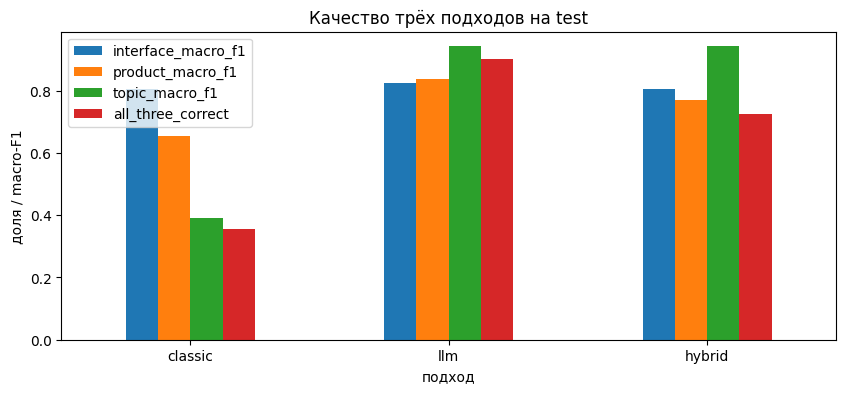

In [28]:
comparison[[f'{field}_macro_f1' for field in FIELDS] + ['all_three_correct']].plot(kind='bar', figsize=(10, 4))
plt.title('Качество трёх подходов на test')
plt.xlabel('подход')
plt.ylabel('доля / macro-F1')
plt.xticks(rotation=0)
plt.show()

### Скорость и ресурсы

- бустинг: время прогноза из первого ноутбука (на одно обращение, без TF-IDF), размер файла модели;
- LLM: среднее время на одно обращение (один запрос), объём модели в памяти
  и сколько из него на видеокарте — по данным Ollama

In [29]:
classic_params = json.load(open('models/classic_params.json', encoding='utf-8'))
classic_speed = pd.read_csv('results/classic_validation.csv')
classic_speed = classic_speed[classic_speed.apply(
    lambda row: classic_params['best_models'][row['field']]['model'] == row['model'], axis=1)]

llm_seconds = pd.Series([record['seconds'] for record in test_records.values()])
loaded = [model for model in requests.get(f'{OLLAMA_URL}/api/ps', timeout=10).json()['models'] if model['name'] == MODEL]

resources = pd.DataFrame({
    'classic': {'секунд на обращение': classic_speed['predict_ms_per_appeal'].sum() / 1000,
                'размер модели, ГБ': os.path.getsize('models/classic_model.pkl') / 1024 ** 3,
                'на видеокарте, ГБ': 0},
    'llm': {'секунд на обращение': llm_seconds.mean(),
            'размер модели, ГБ': loaded[0]['size'] / 1024 ** 3 if loaded else np.nan,
            'на видеокарте, ГБ': loaded[0]['size_vram'] / 1024 ** 3 if loaded else np.nan},
})
display(f'LLM: медиана {llm_seconds.median():.2f} с на обращение, максимум {llm_seconds.max():.2f} с')
resources.round(4)

'LLM: медиана 2.90 с на обращение, максимум 3.06 с'

,classic,llm
секунд на обращение,0.0000,2.9028
"размер модели, ГБ",0.0423,5.7693
"на видеокарте, ГБ",0.0000,5.7693


**Вывод:** LLM на видеокарте NVIDIA тратит около 2,9 с на обращение (разметка validation и test — 40 и 44 минуты)
и занимает около 5,8 ГБ памяти. Бустинг работает на обычном процессоре за доли миллисекунды на обращение
с моделью 43 МБ — на порядки быстрее и легче. Для потока из данных (в среднем около 26 обращений в день)
скорости LLM хватает с большим запасом: дневной поток размечается примерно за полторы минуты.

## Сохранение результатов

In [30]:
comparison.to_csv('results/comparison_test.csv')
resources.to_csv('results/resources.csv')

with open('models/llm_params.json', 'w', encoding='utf-8') as f:
    json.dump({'model': MODEL, 'num_ctx': NUM_CTX, 'agreement_fields': AGREEMENT_FIELDS,
               'thresholds': thresholds_by_approach, 'hybrid_source_by_field': source_by_field,
               'system_prompt': SYSTEM_PROMPT}, f, ensure_ascii=False, indent=2)

reviewed_test = add_review(hybrid_test, thresholds_by_approach['hybrid'])
test_gold[['text'] + FIELDS].loc[reviewed_test.index].join(
    reviewed_test.rename(columns={field: f'{field}_pred' for field in FIELDS})).to_csv(
    'results/hybrid_test_predictions.csv', encoding='utf-8-sig')

## Выводы

**Качество на test (сентябрь)**

| | Бустинг | LLM | Гибрид |
|---|---|---|---|
| Интерфейс, accuracy / macro-F1 | 0,878 / 0,807 | 0,962 / 0,825 | 0,878 / 0,807 |
| Продукт, accuracy / macro-F1 | 0,757 / 0,655 | 0,917 / 0,838 | 0,818 / 0,771 |
| Тематика, accuracy / macro-F1 | 0,571 / 0,390 | 0,977 / 0,943 | 0,977 / 0,943 |
| Все три поля верны | 36% | 90% | 72,5% |
| На ручную проверку | 95% | 7% | 28% |
| Все три поля верны среди принятых автоматически | 93% | 95,5% | 98,5% |

- **Тематика — главное различие подходов.** Бустинг на словах не переносится на новые формулировки того же смысла
  (accuracy 0,57), LLM с определениями классов из справочника опирается на смысл (0,98).
- **Интерфейс и продукт** оба подхода определяют хорошо. LLM на test точнее, но не умеет отвечать `UNKNOWN`:
  на validation recall `UNKNOWN` в интерфейсе и продукте равен 0.
- **Уверенность.** У LLM — вероятность ответа: отсекает 2–5% сомнительных ответов, но не ловит ошибки,
  в которых модель уверена. У гибрида — согласие LLM и бустинга: при согласии ответ почти всегда верен
  (интерфейс 98%, продукт 95% на validation), поэтому среди принятых автоматически гибрид ошибается реже всех.

**Выбор итогового варианта** зависит от того, что важнее заказчику:
- **разгрузить операторов — LLM:** на ручную проверку 7–15% обращений, среди принятых автоматически
  полностью верны 91% (validation) – 95,5% (test);
- **не ошибаться в автоматически принятых — гибрид:** среди принятых полностью верны 95% (validation) – 98,5% (test),
  но оператор проверяет 23–28% обращений.

Предлагаемый вариант — гибрид: ошибку в автоматически проставленных полях никто не увидит, а лишняя ручная проверка
заметна и обходится дешевле. Окончательный выбор — по согласованию с заказчиком.

**Скорость и ресурсы.** Бустинг — доли миллисекунды на обращение на процессоре, модель 43 МБ. LLM — около 2,9 с
на обращение на видеокарте, около 5,8 ГБ памяти. Гибрид использует обе модели, по времени он равен LLM.

**Ограничения и что улучшить**
- Промпт первой версии: LLM почти не ставит `UNKNOWN`. Следующая версия промпта должна это исправить;
  любые изменения промпта проверяются на validation.
- Данные синтетические. Пороги подобраны на августе, а на сентябре точность среди принятых автоматически другая —
  на реальном потоке пороги нужно пересматривать.
- Уверенность модели — не откалиброванная вероятность, а сигнал для выбора порога.